# Step 1: Import all libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings("ignore")

# Step 2: Loading the Dataset

In [3]:
df=pd.read_csv("simple_linear_regression_dataset.csv")

# Step 3: Check the Dataset

In [4]:
df.head()

,Experience_Years,Salary
0,1,22000
1,2,26000
2,3,31000
3,4,35000
4,5,41000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Experience_Years  10 non-null     int64
 1   Salary            10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


In [6]:
df.isnull().sum()

Experience_Years    0
Salary              0
dtype: int64

# Step 4 : Splitting the Data for Features(Input) and Target(output)

In [7]:
x=df[["Experience_Years"]]  # This is your Feature column
y=df["Salary"] # This is your target column

# Step 5: Scatter plot to checking this is in Straight line or not

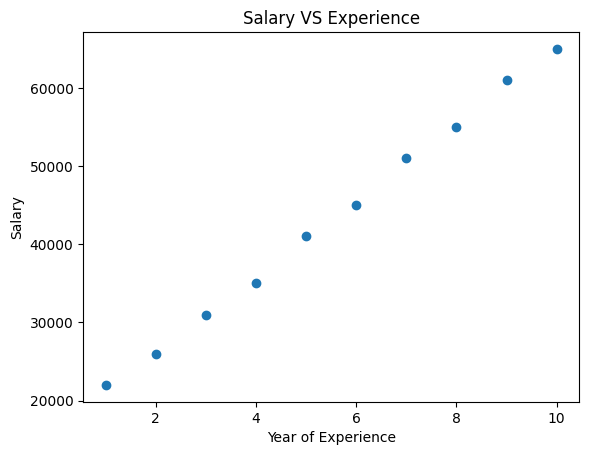

In [8]:
plt.scatter(x,y)
plt.xlabel("Year of Experience")
plt.ylabel("Salary")
plt.title("Salary VS Experience")
plt.show()

In [9]:
corr = df["Experience_Years"].corr(df["Salary"])
print("Correlation:", corr)

Correlation: 0.9992953174831867


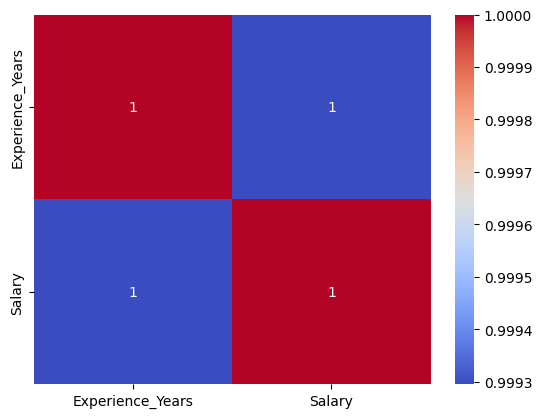

In [17]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

# Step 6: Splitting the data for training and testing

In [10]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

# Step 7: Create and train the linear regression model

In [11]:
from sklearn.linear_model import LinearRegression # model training

model=LinearRegression()

model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[4818.97]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Experience_Years']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.662e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


# Step 8: Predict Salary for test data

In [12]:
y_pred=model.predict(x_test)
y_pred

array([59991.37931034, 26258.62068966])

# Step 9: Now Camparing predicted to actual value

In [13]:
result=pd.DataFrame({"Actual_Value":y_test,"Predicted_Value":y_pred})
result

,Actual_Value,Predicted_Value
8,61000,59991.37931
1,26000,26258.62069


# Step 10: Check Model Performance Matrix

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [15]:
mae=mean_absolute_error(y_test, y_pred)
mse=mean_squared_error(y_test, y_pred)
rmse=np.sqrt(mean_squared_error(y_test, y_pred))
r2=r2_score(y_test, y_pred)

In [16]:
print("mean_absolute_error:", mae)
print("mean_squared_error:", mse)
print("root_mean_squared_error:", rmse)
print("R2_Score:",r2)

mean_absolute_error: 633.6206896551703
mean_squared_error: 542100.1783590964
root_mean_squared_error: 736.2745264906945
R2_Score: 0.9982298769686233


# ---------- Step 11: Plot the best-fit line on the data ----------


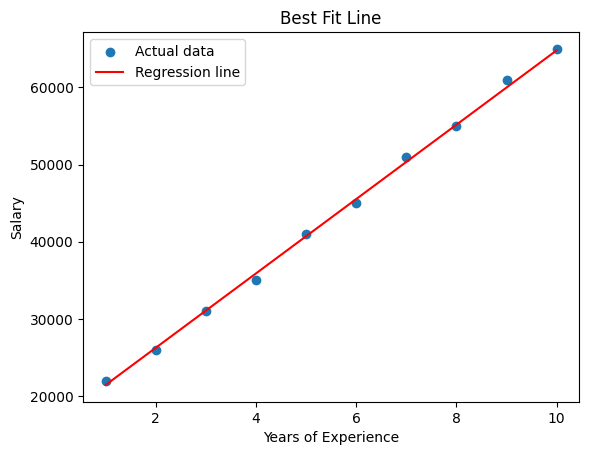

In [18]:
plt.scatter(x, y, label="Actual data")
plt.plot(x, model.predict(x), color="red", label="Regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Best Fit Line")
plt.legend()
plt.show()

# Step 12: Residual plot (final straight-line check) 
# Random scatter around 0 = straight line is a good fit

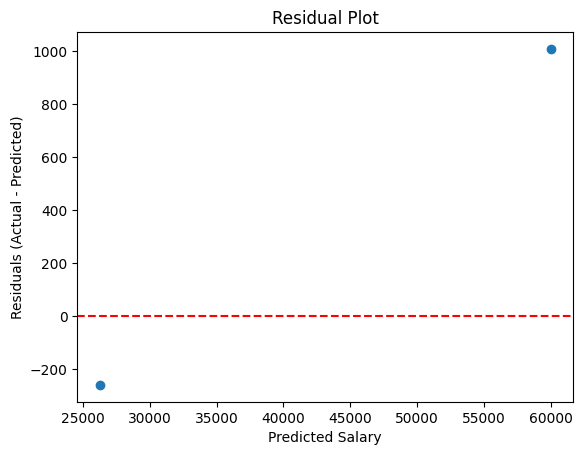

In [19]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

# Step 13: Predict for a new value


In [20]:
new_exp = pd.DataFrame({"Experience_Years": [5]})
print("Predicted salary for 5 years:", model.predict(new_exp)[0])

Predicted salary for 5 years: 40715.517241379304


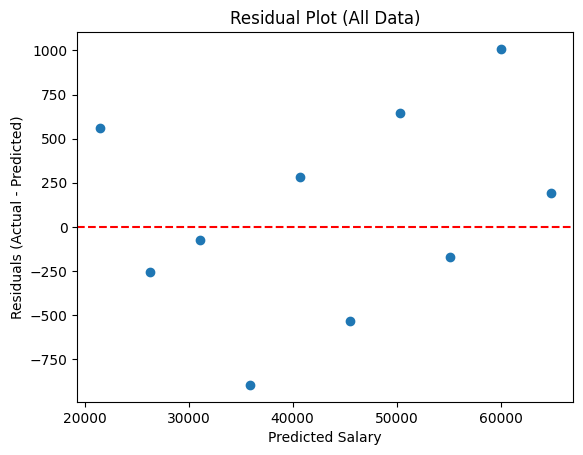

In [21]:
# Residuals using all data
y_all_pred = model.predict(x)
residuals_all = y - y_all_pred

plt.scatter(y_all_pred, residuals_all)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot (All Data)")
plt.show()